In [1]:
import logging
import random
from sklearn.feature_selection import mutual_info_regression
import re
import numpy as np
import pandas as pd
import seaborn as sns
import sympy as sp
import matplotlib.pyplot as plt
from sympy import simplify
from main import run_ga
import threading
import textwrap
import matplotlib as mpl
import os

SEED = 56
np.random.seed(SEED)
mpl.rcParams.update({
    "font.serif": ["Times New Roman"],
    "font.size": 13,
    "axes.titlesize": 13,
    "axes.labelsize": 13,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
})
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s"
 )

differential = False
MAX_DECOMP_STEPS = 40  # soft cap to keep manual decomposition manageable

/home/sandy/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Using device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
CUDA Version: 13.0


In [2]:
def regression_metrics(y_true: np.ndarray, y_pred: np.ndarray):
    residuals = y_true - y_pred
    ss_res = float(np.sum(residuals ** 2))
    ss_tot = float(np.sum((y_true - np.mean(y_true)) ** 2))
    r2 = 1 - ss_res / ss_tot if ss_tot else float("nan")
    rmse = float(np.sqrt(np.mean(residuals ** 2)))
    return r2, rmse

def simplify_with_timeout(expr, timeout_seconds=5):
    """
    Attempt to simplify with a timeout using threading.
    Returns simplified expression or original if timeout occurs.
    """
    result = [None]
    exception = [None]
    
    def target():
        try:
            result[0] = simplify(expr)
        except Exception as e:
            exception[0] = e
    
    thread = threading.Thread(target=target, daemon=True)
    thread.start()
    thread.join(timeout=timeout_seconds)
    
    if thread.is_alive():
        print(f"Warning: Simplification timed out after {timeout_seconds}s, using unsimplified expression")
        return expr
    
    if exception[0]:
        raise exception[0]
    
    return result[0]

def decompose(expr, max_ops=12):
    """
    Recursively break apart expressions so that *no returned node*
    has more than max_ops operations. Large children are broken first.
    """
    steps = []
    counter = [1]

    def wrap(node):
        name = sp.Symbol(f"t{counter[0]}")
        counter[0] += 1
        steps.append((name, node))
        return name

    def process(node):
        # Leaf
        if not node.args:
            return node

        # Recursively process children first
        new_args = [process(arg) for arg in node.args]
        new_node = type(node)(*new_args)

        # After rebuilding, check size
        if new_node.count_ops() > max_ops:
            return wrap(new_node)

        return new_node

    root = process(expr)
    return root, steps


def dmath_block(expr: str) -> list[str]:
    return [r"\begin{dmath*}", expr, r"\end{dmath*}"]


In [3]:
df = pd.read_csv("monsoon.csv")

df_long = df.melt(
    id_vars=["PARAMETER", "YEAR"],
    var_name="MONTH",
    value_name="VALUE"
)

df_pivot = df_long.pivot_table(
    index=["YEAR", "MONTH"],
    columns="PARAMETER",
    values="VALUE"
).reset_index()

month_map = {"JAN": 1, "FEB": 2, "MAR": 3, "APR": 4, "MAY": 5,
             "JUN": 6, "JUL": 7, "AUG": 8, "SEP": 9,
             "OCT": 10, "NOV": 11, "DEC": 12}

df_pivot["MONTH_NUM"] = df_pivot["MONTH"].map(month_map)

df_pivot["DATE"] = pd.to_datetime(
    df_pivot["YEAR"].astype(str) + "-" + df_pivot["MONTH_NUM"].astype(str)
)
df_pivot.set_index("DATE", inplace=True)

df_final = df_pivot.drop(columns=["YEAR", "MONTH", "MONTH_NUM"])

def sanitize(name: str) -> str:
    s = name.strip()
    s = re.sub(r"\W+", "_", s)
    if s and s[0].isdigit():
        s = f"v_{s}"
    s = s[:2]
    return s

col_map = {c: sanitize(c) for c in df_final.columns}
df_final.rename(columns=col_map, inplace=True)

df_final = (
    df_final.apply(pd.to_numeric, errors="coerce")
    .replace([pd.NA, float("inf"), -float("inf")], pd.NA)
    .dropna()
)
if differential:
    for column in df_final.columns:
        df_final[f"d{column}"] = np.gradient(df_final[column].to_numpy(dtype=float))
%matplotlib inline


Mutual information for target 'Pr':


,MI
So,0.364267
Sp,0.240189
Te,0.077978


Mutual information for target 'So':


,MI
Te,0.826852
Sp,0.521621
Pr,0.361611


Mutual information for target 'Sp':


,MI
So,0.504178
Te,0.382539
Pr,0.248760


Mutual information for target 'Te':


,MI
So,0.827511
Sp,0.377418
Pr,0.077515


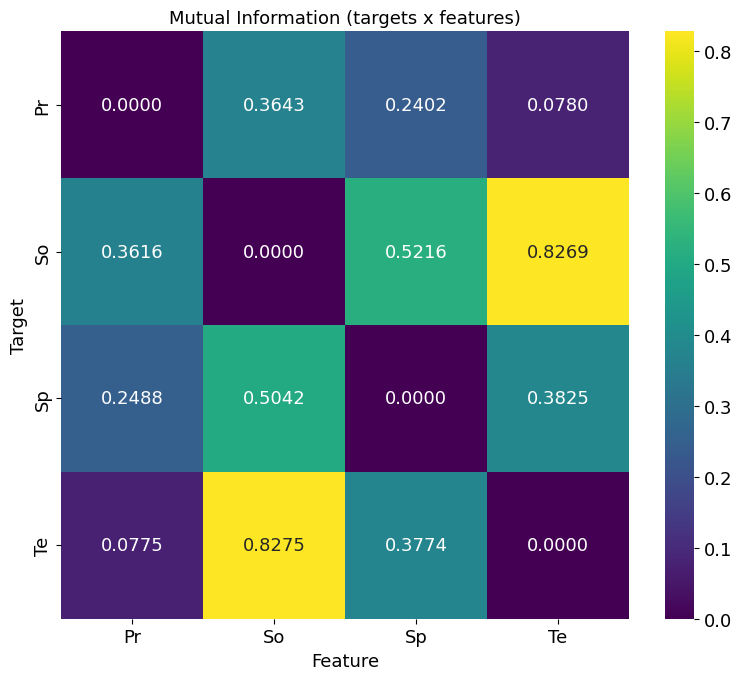

In [4]:
# compute MI with every column as target
targets = list(df_final.columns)
if len(df_final.columns) <= 1:
    print("Not enough columns to compute mutual information (need at least 1 feature and 1 target).")
else:
    mi_results = {}
    for t in df_final.columns:
        # use all other columns as features for this target
        feature_df = df_final.drop(columns=[t])
        X = feature_df.to_numpy(dtype=float)
        feature_names = feature_df.columns.tolist()

        y = df_final[t].to_numpy(dtype=float)
        mi = mutual_info_regression(X, y, discrete_features=False, random_state=SEED)
        mi_series = pd.Series(mi, index=feature_names).sort_values(ascending=False)
        mi_results[t] = mi_series
        print(f"Mutual information for target '{t}':")
        display(mi_series.to_frame(name="MI"))

    # combined table (targets x features)
    mi_df = pd.DataFrame(mi_results).T.fillna(0)
    plt.figure(figsize=(max(8, 0.8 * mi_df.shape[1]), 3 + mi_df.shape[0]))
    sns.heatmap(mi_df, annot=True, fmt=".4f", cmap="viridis")
    plt.title("Mutual Information (targets x features)")
    plt.xlabel("Feature")
    plt.ylabel("Target")
    plt.tight_layout()
    plt.savefig(f"mi.pdf", bbox_inches='tight')
    plt.show()


Correlation matrix: PARAMETER        Pr        So        Sp        Te
PARAMETER                                        
Pr         1.000000  0.482160  0.585487 -0.421531
So         0.482160  1.000000  0.788807 -0.789661
Sp         0.585487  0.788807  1.000000 -0.709625
Te        -0.421531 -0.789661 -0.709625  1.000000


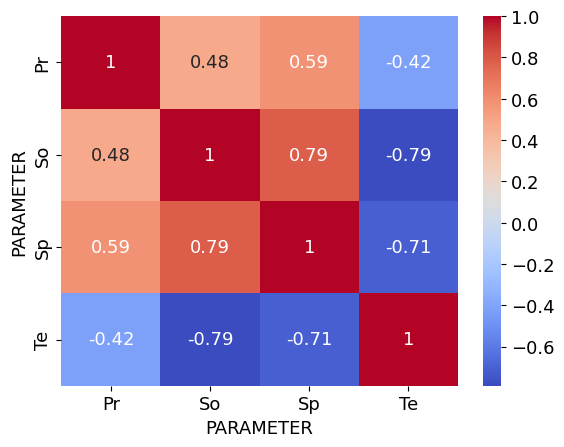

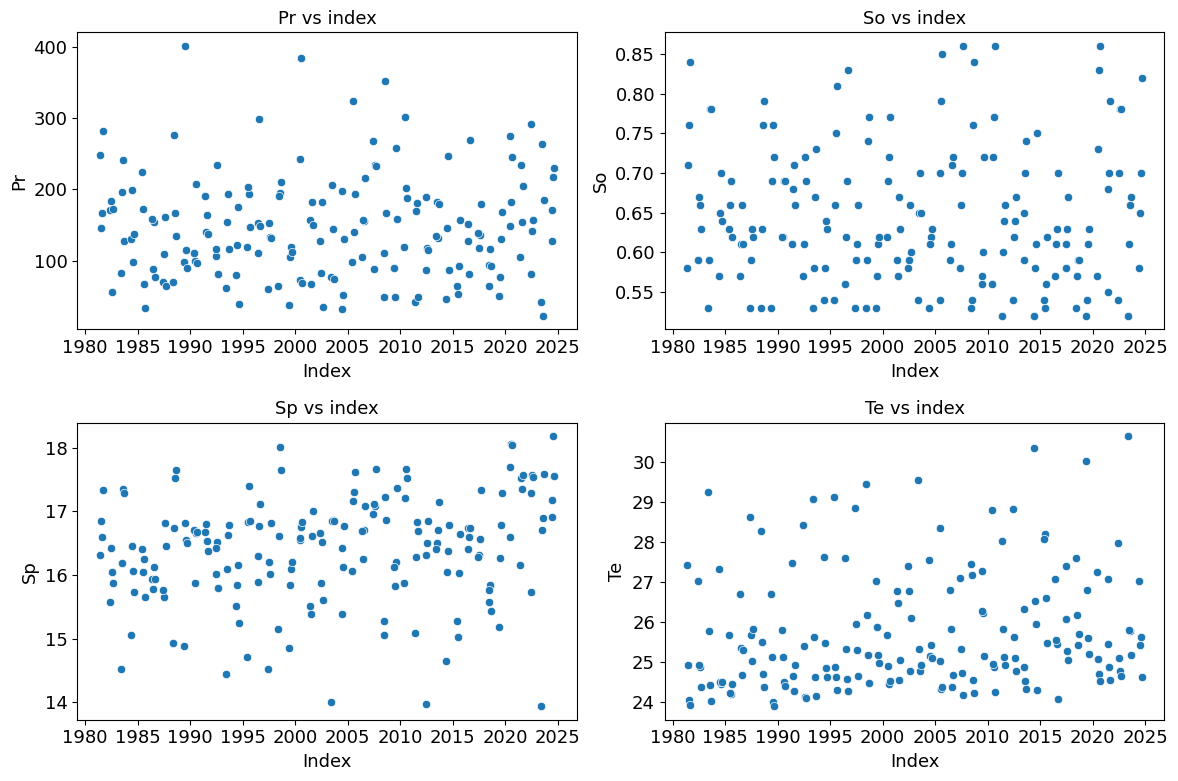

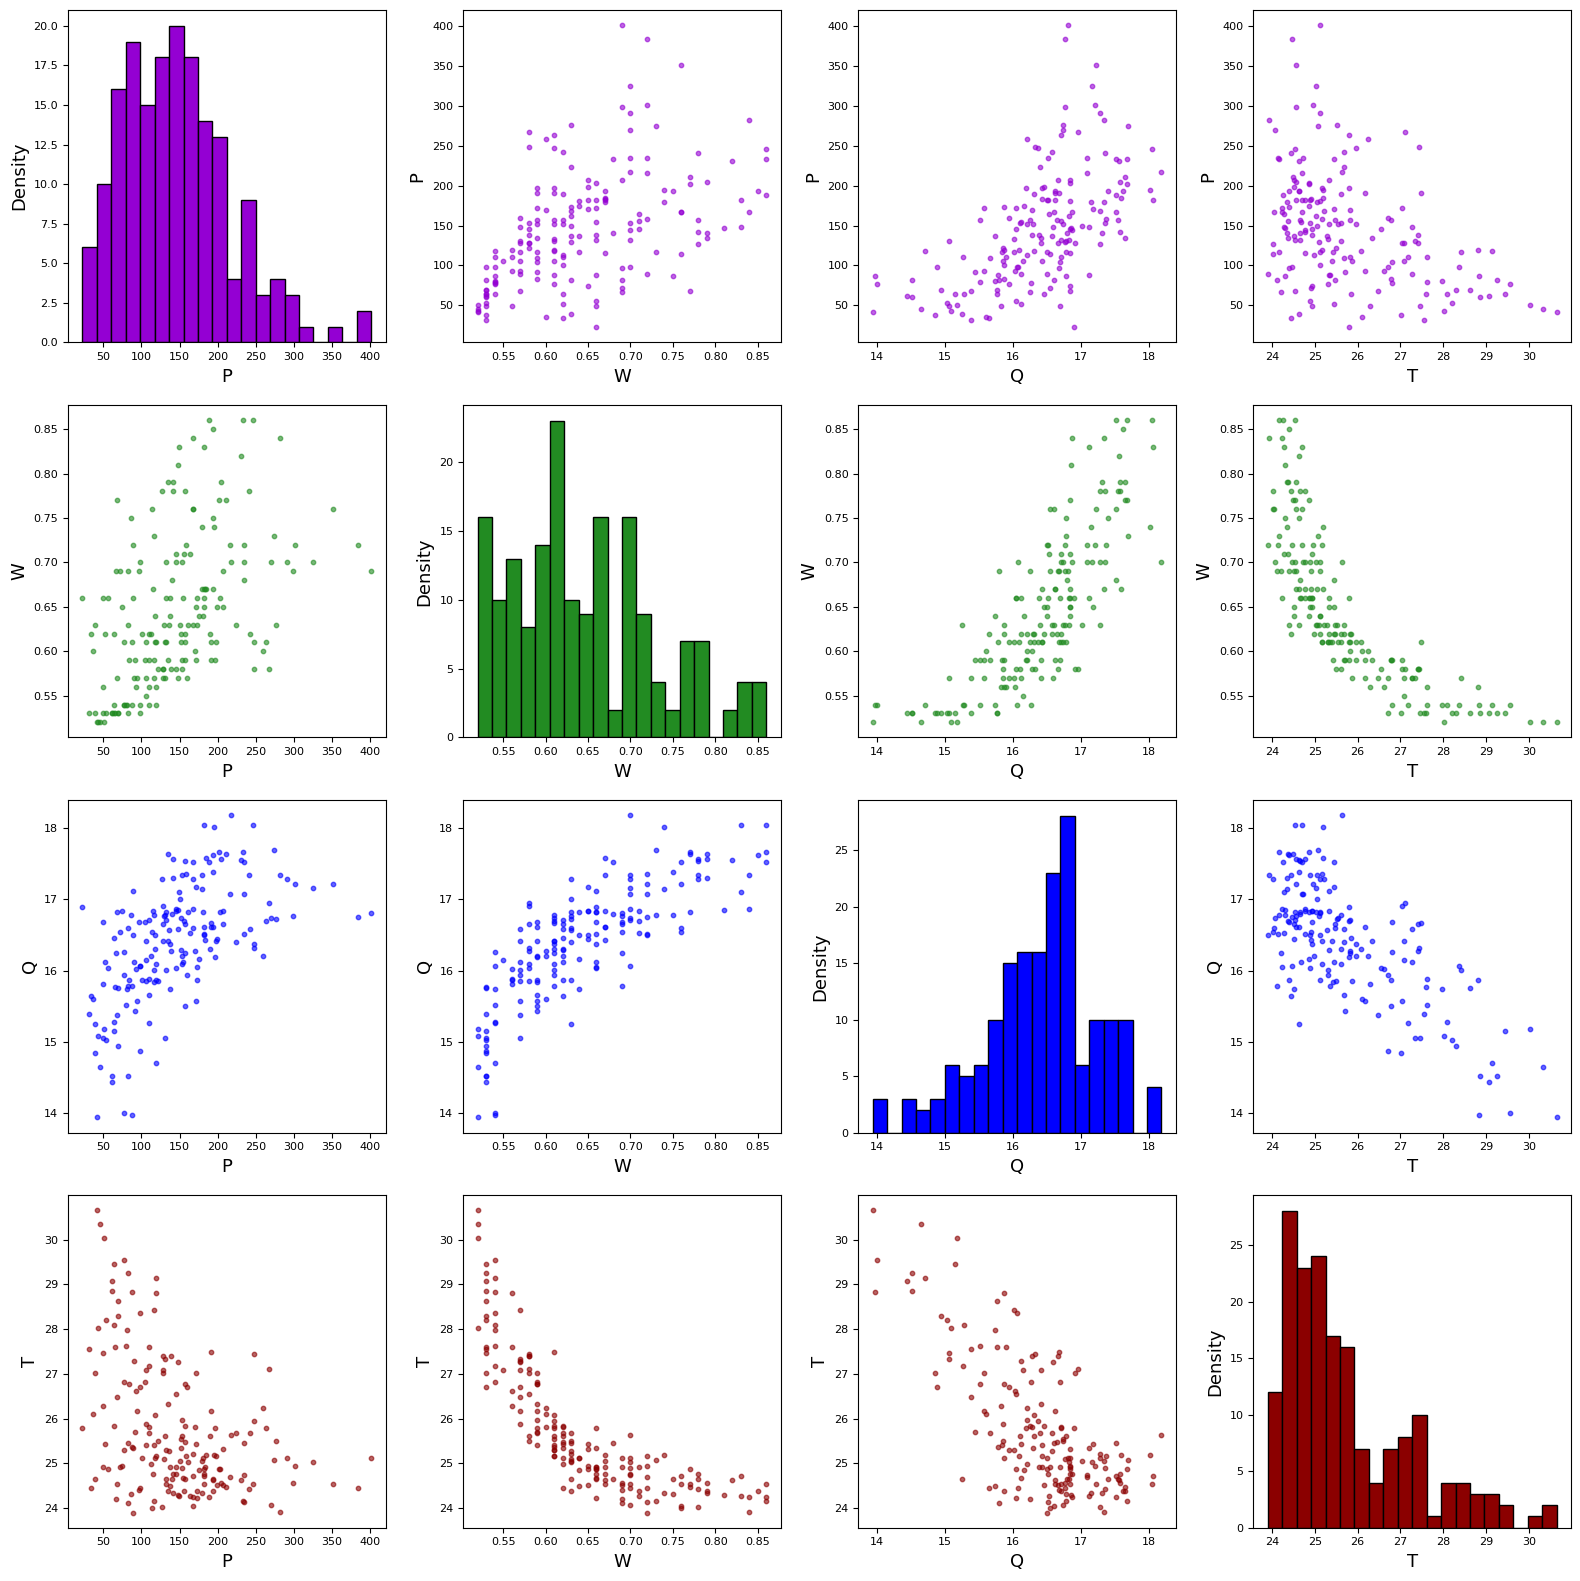

In [5]:
print("Correlation matrix:", df_final.corr())
sns.heatmap(data=df_final.corr(), annot=True, cmap="coolwarm")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, col in zip(axes, df_final.columns):
    sns.scatterplot(x=df_final.index, y=df_final[col], ax=ax)
    ax.set_title(f"{col} vs index")
    ax.set_xlabel("Index")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(16, 16))

# Colors for each row
row_colors = ['darkviolet', 'forestgreen', 'blue', 'darkred']
vars = ['Pr', 'So', 'Sp', 'Te']
chvars = {'Pr': 'P', 'So': 'W', 'Sp': 'Q', 'Te': 'T'}
for i in range(4):
    for j in range(4):
        ax = axes[i, j]
        if i == j:
            # Diagonal: Histogram
            if vars[i] == 'Pr':
                ax.hist(df_final[vars[i]], bins=20, color='darkviolet', edgecolor='black')
                ax.set_xlabel('P')
                ax.set_ylabel('Density')
            elif vars[i] == 'So':
                ax.hist(df_final[vars[i]], bins=20, color='forestgreen', edgecolor='black')
                ax.set_xlabel('W')
                ax.set_ylabel('Density')
            elif vars[i] == 'Sp':
                ax.hist(df_final[vars[i]], bins=20, color='blue', edgecolor='black')
                ax.set_xlabel('Q')
                ax.set_ylabel('Density')
            else:  # Te
                ax.hist(df_final[vars[i]], bins=20, color='darkred', edgecolor='black')
                ax.set_xlabel('T')
                ax.set_ylabel('Density')
        else:
            color = row_colors[i]
            ax.scatter(df_final[vars[j]], df_final[vars[i]], color=color, alpha=0.6, s=10)
            ax.set_xlabel(chvars[vars[j]])
            ax.set_ylabel(chvars[vars[i]])
        
        # Adjust layout
        ax.tick_params(axis='both', which='major', labelsize=8)

plt.tight_layout()
plt.savefig(f"pairplot.pdf", bbox_inches='tight')
plt.show()


In [6]:
target = "Sp"
target_full = next((orig for orig, alias in col_map.items() if alias == target), target)
feature_cols = [c for c in df_final.columns if c != target]
print(df_final.head())

X = df_final[feature_cols].to_numpy(dtype=float)
y = df_final[target].to_numpy(dtype=float)

unary_funcs = {
        'sin': (np.sin, sp.sin),
        'cos': (np.cos, sp.cos),
        'tan': (np.tan, sp.tan),
        'exp': (np.exp, sp.exp),
        'sqrt': (np.sqrt, sp.sqrt)
    }

PARAMETER       Pr    So     Sp     Te
DATE                                  
1981-08-01  167.08  0.76  16.60  24.05
1981-07-01  145.41  0.71  16.84  24.93
1981-06-01  247.83  0.58  16.32  27.44
1981-09-01  281.74  0.84  17.34  23.92
1982-08-01   55.79  0.66  16.04  24.88


In [7]:
print(f"Running genetic algorithm for '{target}' against {feature_cols}")
ga_params = {
    'pop_size': 2000,
    'gens': 300,
    'max_init_depth': 4,
    'max_depth': 10,
    'crossover_rate': 0.85,
    'mutation_rate': 0.2,
    'tournament_k': 5,
    'elitism': 15,
    'use_learned_crossover': True,
    'selector_lr': 0.0005,
    'use_transformer': False,
    'transformer_heads': 8,
    'transformer_layers': 4,
    'mlp_layers': 15,
    'mlp_hidden_dim': 256,
    'mlp_activation': "gelu",
    'mlp_dropout': 0.1,
    'complexity_coef': 1e-5,
    'inclusion_coef': 0.5,
    'prob_const': 0.35,
    'const_range': (-3, 3),
    'point_mutation_prob': 0.1,
    'selector_update_freq': 3,
    'temperature': 0.7,
    'critic_weight': 0.6,
    'entropy_weight': 0.02,
    'seed': SEED,
}

best, best_score = run_ga(
    X,
    y,
    var_names=feature_cols,
    unary_funcs=unary_funcs,
    stopping_metric="r2",
    stopping_threshold=None,
    verbose=True,
    print_freq=10,
    **ga_params
)

if best is None:
    raise RuntimeError("Genetic algorithm did not return a valid expression.")

sym_expr = simplify_with_timeout(best.to_sympy(), timeout_seconds=30)
feature_values = {name: df_final[name].to_numpy(dtype=float) for name in feature_cols}
y_pred = best.evaluate(feature_values)
r2, rmse = regression_metrics(y, y_pred)

# compute MAPE and SMAPE (robust to zeros)
eps = 1e-8
mape = float(np.mean(np.abs((y - y_pred) / np.where(np.abs(y) < eps, eps, y)))) * 100.0
smape = float(
    np.mean(
        2.0 * np.abs(y - y_pred)
        / np.where((np.abs(y) + np.abs(y_pred)) < eps, eps, (np.abs(y) + np.abs(y_pred)))
    )
) * 100.0

print(f"Best score (MSE + penalty): {best_score:.6f}")
print(f"Sympy expression: {sym_expr}")
print(f"R2: {r2:.4f}, RMSE: {rmse:.4f}, MAPE: {mape:.4f}%, SMAPE: {smape:.4f}%")

Running genetic algorithm for 'Sp' against ['Pr', 'So', 'Te']
Using learned subtree crossover with MLP (15 layers, 256 hidden, gelu activation, 0.1 dropout, A2C (with critic))


GA generations:   0%|          | 0/300 [00:00<?, ?gen/s]

Gen   1 best MSE+penalty: 2.0712 R²: -0.550703 expr: (exp(2.759) - (2.22 / Pr))
Gen  10 best MSE+penalty: 0.591608 R²: 0.143968 expr: ((exp(2.739) + (sqrt(Pr) / (exp(2.196) - (Pr / (Te + Pr))))) + ((2.76 / (exp(2.196) - (Pr / ((-2.899 + 0.4075) + So)))) / (2.149 - 2.499)))
Gen  20 best MSE+penalty: 0.289065 R²: 0.582095 expr: (cos(tan((sin(((exp(2.739) + (((exp(2.599) - ((Te - cos(-2.32)) / (1.318 - Pr))) - ((exp(2.196) - (Pr / Pr)) / Te)) / (-2.899 - (Pr + tan(0.06057))))) / 2.728)) / So))) + exp(2.784))
Gen  30 best MSE+penalty: 0.204115 R²: 0.705310 expr: (cos(tan((sin(((exp(2.739) + (((exp(2.599) - ((Te - cos(-2.32)) / (1.318 - Pr))) - (exp(2.784) / Pr)) / (-2.899 - (Pr + tan(0.06057))))) / 2.728)) / So))) + (cos(tan((sin(((exp(2.739) + (sqrt(2.753) / (-2.899 - (Pr + tan(0.06057))))) / 2.728)) / So))) + exp(2.784)))
Gen  40 best MSE+penalty: 0.197921 R²: 0.714335 expr: (cos(tan((sin(((exp(2.739) + (((exp(2.599) - ((Te - (Pr - tan(Pr))) / (1.318 - Pr))) - (1.664 / exp(exp(2.712)))) 

In [8]:
sym_expr = simplify_with_timeout(best.to_sympy(), timeout_seconds=5000)

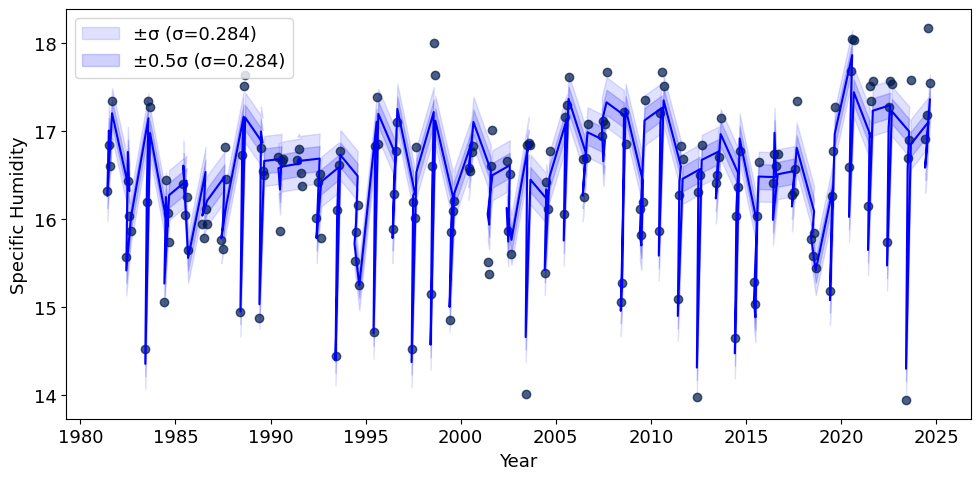

In [9]:
residuals = y - y_pred
# use standard deviation of residuals as uncertainty (1σ)
color_mapping = {
    'Temperature': 'darkred',
    'Specific Humidity': 'blue',
    'Precipitation': 'darkviolet',
    'Soil Moisture': 'forestgreen'
}
plt.figure(figsize=(10, 5))
plt.scatter(df_final.index, y, alpha=0.7, zorder=5, color="#001a4d")
plt.plot(df_final.index, y_pred, color=color_mapping.get(target_full.strip(), "red"), zorder=6)

# shaded ±1σ, ±2σ, ±3σ bands around prediction
sigma = float(np.std(residuals))
upper1 = y_pred + 0.5 * sigma
lower1 = y_pred - 0.5 * sigma
upper2 = y_pred + 1 * sigma
lower2 = y_pred - 1 * sigma

# widest (3σ) first so it sits behind narrower bands
plt.fill_between(df_final.index, lower2, upper2, color=color_mapping.get(target_full.strip(), "red"), alpha=0.12, label=f"±σ (σ={sigma:.3f})", zorder=2)
plt.fill_between(df_final.index, lower1, upper1, color=color_mapping.get(target_full.strip(), "red"), alpha=0.18, label=f"±0.5σ (σ={sigma:.3f})", zorder=3)

plt.xlabel("Year")
plt.ylabel(f"{target_full}")
plt.legend()
plt.tight_layout()
plt.savefig(f"predict_{target}.pdf", bbox_inches='tight')
plt.show()


In [10]:
expr_latex = sp.latex(sym_expr)
root_symbol, decomposition_steps = decompose(sym_expr, max_ops=4)

print("Manual decomposition steps (truncated):")
for sym_name, sub_expr in decomposition_steps:
    print(f"{sym_name} = {sub_expr}")
print(f"e1 = {root_symbol}")

latex_filename = f"{target}_expression.tex"
latex_lines = []
latex_lines.append(r"\documentclass{article}")
latex_lines.append(r"\usepackage{amsmath}")
latex_lines.append(r"\usepackage{pdflscape}")
latex_lines.append(r"\usepackage{geometry}")
latex_lines.append(r"\usepackage{listings}")
latex_lines.append(r"\geometry{a4paper,margin=1.5cm}")
latex_lines.append(r"\begin{document}")

# === Hyperparameters Section ===
latex_lines.append(r"\section*{Hyperparameters}")
latex_lines.append(r"\begin{itemize}")

# Human-readable names mapping
param_names = {
    'pop_size': 'Population Size',
    'gens': 'Generations',
    'max_init_depth': 'Max Initial Depth',
    'max_depth': 'Max Depth',
    'crossover_rate': 'Crossover Rate',
    'mutation_rate': 'Mutation Rate',
    'tournament_k': 'Tournament Size',
    'elitism': 'Elitism',
    'use_learned_crossover': 'Use Learned Crossover',
    'selector_lr': 'Selector Learning Rate',
    'use_transformer': 'Use Transformer',
    'transformer_heads': 'Transformer Heads',
    'transformer_layers': 'Transformer Layers',
    'mlp_layers': 'MLP Layers',
    'mlp_hidden_dim': 'MLP Hidden Dim',
    'mlp_activation': 'MLP Activation',
    'mlp_dropout': 'MLP Dropout',
    'complexity_coef': 'Complexity Coefficient',
    'inclusion_coef': 'Inclusion Coefficient',
    'prob_const': 'Probability Constant',
    'const_range': 'Constant Range',
    'point_mutation_prob': 'Point Mutation Probability',
    'selector_update_freq': 'Selector Update Frequency',
    'temperature': 'Temperature',
    'critic_weight': 'Critic Weight',
    'entropy_weight': 'Entropy Weight',
    'seed': 'Random Seed'
}

for param_key, param_value in ga_params.items():
    readable_name = param_names.get(param_key, param_key.replace('_', ' ').title())
    
    if isinstance(param_value, str):
        safe_value = param_value.upper()
    elif isinstance(param_value, bool):
        safe_value = str(param_value)
    elif isinstance(param_value, tuple):
        safe_value = str(param_value)
    elif isinstance(param_value, float) and param_value < 0.01:
        safe_value = f"{param_value:.1e}"
    else:
        safe_value = str(param_value)
    
    latex_lines.append(rf"\item \textbf{{{readable_name}:}} {safe_value}")

latex_lines.append(r"\end{itemize}")
latex_lines.append(r"\section*{Performance Metrics}")
latex_lines.append(r"\begin{itemize}")
latex_lines.append(rf"\item \textbf{{R²:}} {r2:.4f}")
latex_lines.append(rf"\item \textbf{{RMSE:}} {rmse:.4f}")
latex_lines.append(rf"\item \textbf{{MAPE:}} {mape:.2f}\%")
latex_lines.append(rf"\item \textbf{{SMAPE:}} {smape:.2f}\%")
latex_lines.append(rf"\item \textbf{{Best Score (MSE + penalty):}} {best_score:.6f}")
latex_lines.append(r"\end{itemize}")

# === Manual decomposition listing ===
latex_lines.append(r"\subsection*{Manual Decomposition}")
latex_lines.append(r"\begin{itemize}")
for sym_name, sub_expr in decomposition_steps:
    latex_lines.append(
        f"\\item ${sp.latex(sym_name)} = {sp.latex(sub_expr)}$"
    )
latex_lines.append(f"\\item $e_{{1}} = {sp.latex(root_symbol)}$")
latex_lines.append(r"\end{itemize}")


# === Reduced Expression – BULLETPROOF VERSION ===
latex_lines.append(r"\subsection*{Reduced Expression}")

# Convert the huge expression to raw LaTeX string once
huge_latex = sp.latex(sym_expr)

if len(huge_latex) > 8000:  # threshold: if it's truly insane → special treatment
    latex_lines.append(r"\noindent\textbf{Warning:} The symbolically simplified expression is extremely large "
                       r"(> " + f"{len(huge_latex):,} characters) and cannot be reliably typeset as math "
                       r"on a printed page without manual intervention.\vspace{1em}")

    latex_lines.append(r"The expression is therefore provided in the following forms:\vspace{1em}")
    latex_lines.append(r"\begin{itemize}")
    latex_lines.append(r"\item As a readable \texttt{python} function in the repository "
                       r"(\texttt{reduced\_pressure.py})")
    latex_lines.append(r"\item As raw \LaTeX{} source in \texttt{supplementary/reduced\_pressure.tex}")
    latex_lines.append(r"\item Below in a scrollable, line-wrapped code block (for copy-paste)")
    latex_lines.append(r"\end{itemize}\vspace{1em}")

    # KEY FIX: listings with breaklines=true → wraps ANYWHERE, no overfull ever
    latex_lines.append(r"\begingroup")
    latex_lines.append(r"\footnotesize")  # Smaller font for vertical space
    latex_lines.append(r"\lstset{")  # Global settings for this block
    latex_lines.append(r"  basicstyle=\footnotesize\ttfamily,")
    latex_lines.append(r"  breaklines=true,")
    latex_lines.append(r"  breakatwhitespace=false,")
    latex_lines.append(r"  columns=fixed,")
    latex_lines.append(r"  frame=single,")
    latex_lines.append(r"  backgroundcolor=\color{gray!10},")
    latex_lines.append(r"  xleftmargin=0.5em,")
    latex_lines.append(r"  xrightmargin=0.5em")
    latex_lines.append(r"}")
    latex_lines.append(r"\begin{lstlisting}[language=TeX]")  # Treat as TeX for syntax-ish highlighting
    latex_lines.append(f"e1 = {huge_latex}")
    latex_lines.append(r"\end{lstlisting}")
    latex_lines.append(r"\endgroup")

    # Save separately for full typesetting if needed
    os.makedirs("supplementary", exist_ok=True)
    supp_path = "supplementary/reduced_pressure.tex"
    with open(supp_path, "w", encoding="utf-8") as f:
        f.write(r"% Full reduced pressure expression (auto-generated)" + "\n")
        f.write(r"% Paste this into your own document if you want to try manual breaking." + "\n\n")
        f.write(r"\documentclass{article}" + "\n")
        f.write(r"\usepackage{amsmath}" + "\n")
        f.write(r"\usepackage{breqn}" + "\n")  # They can try breqn if brave
        f.write(r"\begin{document}" + "\n")
        f.write(r"\end{document}" + "\n")
    
    latex_lines.append(r"\vspace{1em}")
    latex_lines.append(r"\noindent Full raw \LaTeX{} also saved to \texttt{" + supp_path.replace('_', r'\_') + r"}.")

latex_lines.append(r"\end{document}")

# Write the main file
with open(f"{target}_expression.tex", "w", encoding="utf-8") as f:
    f.write("\n".join(latex_lines))

Manual decomposition steps (truncated):
t1 = sin(sin(Te - (Te - 0.932673661417481)/Pr))
t2 = sin(Te + tan(Pr - Te)/Pr)
t3 = (-8.98781653545383 - 2.6796023195273*t1/So)*sin(t2)
t4 = -cos(tan(cos(Te - 2.8236818554625)))
t5 = sin(sin(Te - (Te + t4)/Pr))
t6 = 1/(-8.98781653545383 + t5*(Te - 2.32048195430829)/So)
t7 = cos(Te - 2.32048195430829) + 2.7599397743342/cos(0.65413649449199*t6 + 5.67205477072444)
t8 = tan(sin(0.133849112924908*Pr + 0.0049052392678502)/So)
t9 = 1/(-t8*sin(t7) - 0.681408703494794)
t10 = sin(cos(Te - 2.32048195430829) + 2.7599397743342/Pr)
t11 = 0.366612788118867*cos(tan(Pr - 0.179924245921533)) + 5.93473124283401
t12 = -sin(t10 - 1.32192923204513/Pr)*tan(sin(t11)/So)
t13 = -1/((t12 - 0.681408703494794)*(t9 + 16.1880093525537))
t14 = t13 + exp(cos(Te + 1.36281740698959)) - (Te + 0.681408703494794)/Pr
t15 = sin(0.366612788118867*t14/(t3 - 8.98781653545383) + 5.67205477072444)
t16 = 0.366612788118867*Pr + 0.366612788118867*cos(tan(Pr - 0.179924245921533)) - 0.0659625294

In [11]:
sym_expr


cos(tan(sin(5.67205477072444 + 0.366612788118867*(exp(cos(Te + 1.36281740698959)) - 1/((16.1880093525537 + 1/(-sin(cos(Te - 2.32048195430829) + 2.7599397743342/cos(5.67205477072444 + 0.65413649449199/(-8.98781653545383 + (Te - 2.32048195430829)*sin(sin(Te - (Te - cos(tan(cos(Te - 2.8236818554625))))/Pr))/So)))*tan(sin(0.133849112924908*Pr + 0.0049052392678502)/So) - 0.681408703494794))*(-sin(sin(cos(Te - 2.32048195430829) + 2.7599397743342/Pr) - 1.32192923204513/Pr)*tan(sin(0.366612788118867*cos(tan(Pr - 0.179924245921533)) + 5.93473124283401)/So) - 0.681408703494794)) - (Te + 0.681408703494794)/Pr)/((-8.98781653545383 - 2.6796023195273*sin(sin(Te - (Te - 0.932673661417481)/Pr))/So)*sin(sin(Te + tan(Pr - Te)/Pr)) - 8.98781653545383))/So)) + cos(tan(sin(0.366612788118867*(13.4473622683011 - (-2.8236818554625*So*(-Pr + tan(Pr + 0.98197187199823) - 2.89929305296405)/((13.4473622683011 - 1/(-sin(cos(Te - 2.32048195430829))*tan(sin(0.366612788118867*cos(tan(Pr - 0.179924245921533)) + 5.9347

In [12]:
best.to_string()

'(cos(tan((sin(((exp(2.739) + (((exp(2.599) - ((((((Te - cos((Te - cos(-2.32)))) / Pr) - (-2.824 / (sin(sin((Te - So))) * ((((exp(2.599) - (((Pr / (cos(-2.32) - (sin((cos((Te + -2.32)) + (2.76 / Pr))) * tan((sin(((exp(2.739) + ((-2.68 - ((Pr / ((-2.899 - (((-2.68 / Pr) - (sin(cos(2.951)) * (cos(-1.808) + exp(2.788)))) + -2.899)) - (sin((exp(exp(2.739)) - ((0.1799 - cos(-2.32)) / (Pr - cos(-2.32))))) * (-2.68 / Pr)))) / -0.6408)) / (-0.4893 - (Pr + tan((Te - Pr)))))) / 2.728)) / So))))) - Pr) / Te)) - ((Pr / (cos(-2.32) - (sin(cos((Te + -2.32))) * tan((sin(((cos(tan((Pr - 0.1799))) + exp(2.784)) / 2.728)) / So))))) / Pr)) / (-2.899 - (Pr + tan((cos(2.951) - Pr))))) / So)))) - ((Pr / (cos(-2.32) - (sin((cos((Te + -2.32)) + (2.76 / Pr))) * tan((sin(((exp(2.739) + ((-2.68 - ((Pr / ((-2.899 - ((exp(2.196) - (sin(cos(2.951)) * (-0.6408 + exp(2.788)))) + -2.899)) - (sin((Pr / 2.657)) * ((2.728 - (sin(cos(2.951)) * (cos(-2.32) + exp(2.788)))) / Pr)))) / -0.6408)) / (-0.4893 - (Pr + tan(((Pr - 